In [44]:
import numpy as np
from spidercat.utils import load_solution_triplet
from spidercat.spanning_tree import match_forest_leaves_to_marked_edges, inject_root_nodes
from spidercat.circuit_extraction import expand_graph_and_forest
from spidercat.fault_analysis import compute_boundary_fault_table, build_graph_dem
from spidercat.draw import draw_forest_on_graph
from spidercat.draw import display_digraph_on_graph
from spidercat.circuit_extraction import build_traversal_digraph
from spidercat.weight_optimization import (
    exhaustive_weight_search,
    greedy_weight_search,
    simulated_annealing_weight_search
)


%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


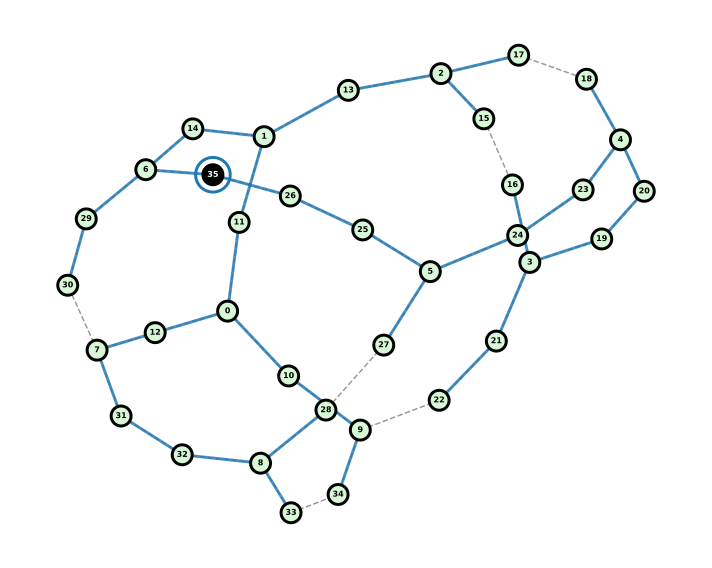

In [72]:
grf, forest, M, matchings = load_solution_triplet(25, 2, 1)
matchings = match_forest_leaves_to_marked_edges(grf, forest, M)
G_exp, F_exp = expand_graph_and_forest(grf, forest, M, matchings)
roots = inject_root_nodes(G_exp, F_exp)
draw_forest_on_graph(G_exp, F_exp, roots)

In [73]:
dem = build_graph_dem(G_exp, F_exp, root=roots[0], cycle_basis_mode="fundamental")
for e in dem.edges:
    detectors, logicals = dem.edge_targets(e)
    print(f"Edge {e}: D{detectors}, L{logicals}")

Edge (0, 10): D[1, 5], L[0, 24]
Edge (0, 11): D[0, 1, 4], L[0, 2, 18, 21, 22, 23, 24]
Edge (0, 12): D[0, 4, 5], L[2, 18, 21, 22, 23]
Edge (1, 11): D[0, 1, 4], L[0, 1, 2, 18, 21, 22, 23, 24]
Edge (1, 13): D[2, 3], L[3, 5, 7]
Edge (1, 14): D[0, 1, 2, 3, 4], L[0, 1, 2, 3, 5, 7, 18, 21, 22, 23, 24]
Edge (2, 13): D[2, 3], L[5, 7]
Edge (2, 15): D[2], L[5]
Edge (2, 17): D[3], L[7]
Edge (3, 16): D[2], L[6]
Edge (3, 19): D[1, 2], L[6, 11, 12]
Edge (3, 21): D[1], L[11, 12]
Edge (4, 18): D[3], L[8]
Edge (4, 20): D[1, 2], L[6, 9, 10, 11, 12]
Edge (4, 23): D[1, 2, 3], L[6, 8, 9, 10, 11, 12]
Edge (5, 24): D[1, 2, 3], L[6, 8, 9, 10, 11, 12, 13, 14]
Edge (5, 25): D[1, 2, 3, 4], L[6, 8, 9, 10, 11, 12, 13, 14, 17]
Edge (5, 27): D[4], L[17]
Edge (6, 14): D[0, 1, 2, 3, 4], L[0, 1, 2, 3, 4, 5, 7, 18, 21, 22, 23, 24]
Edge (6, 29): D[0], L[19, 20]
Edge (6, 35): D[1, 2, 3, 4], L[6, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]
Edge (7, 12): D[0, 4, 5], L[18, 21, 22, 23]
Edge (7, 31): D[4, 5], L[18, 21, 22, 23]
Edge (

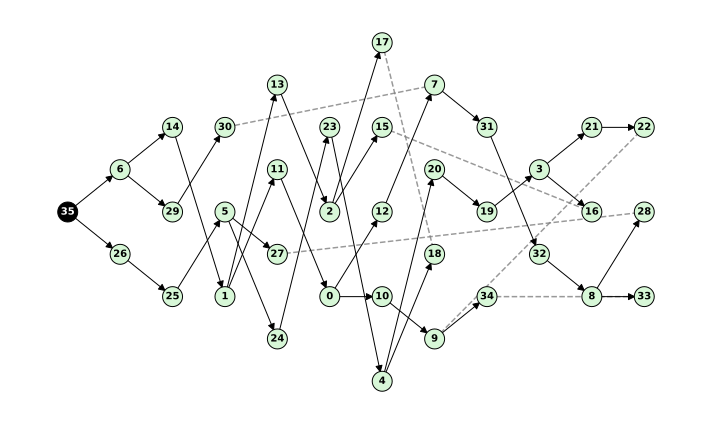

In [74]:
digraph = build_traversal_digraph(G_exp, F_exp, roots[0])
display_digraph_on_graph(digraph, G_exp, figsize=(10, 6))

In [75]:
table = compute_boundary_fault_table(G_exp, F_exp, L=5, root=roots)
print("Table build")

candidates = exhaustive_weight_search(table, fix_boundary_weight_one=True)
print("Best exhaustive:    ", candidates[0].polynomial_str)
print("Worst exhaustive:   ", candidates[-1].polynomial_str)
# print("Edge weights:", candidates[0].edge_weights)  # flag edges are (w_a, w_b) tuples

# 2. Greedy search
greedy_cand = greedy_weight_search(table, fix_boundary_weight_one=True)
print("Greedy:             ", greedy_cand.polynomial_str)

# 3. Simulated annealing (starting from greedy)
sa_cand = simulated_annealing_weight_search(table, fix_boundary_weight_one=True, num_steps=1_000)
print("Simulated Annealing:", sa_cand.polynomial_str)

Table build
Best exhaustive:     25p + 330p^2 + 3477p^3 + 33089p^4 + 280322p^5
Worst exhaustive:    25p + 338p^2 + 3678p^3 + 35580p^4 + 303359p^5
Greedy:              25p + 331p^2 + 3496p^3 + 33236p^4 + 280698p^5
Simulated Annealing: 25p + 330p^2 + 3477p^3 + 33089p^4 + 280322p^5


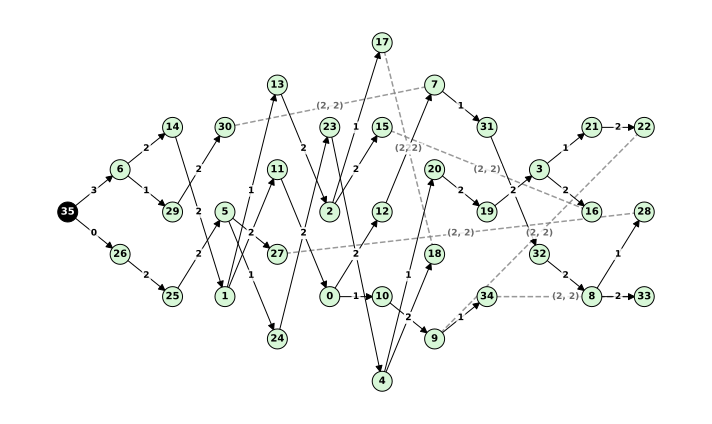

In [76]:
display_digraph_on_graph(digraph, G_exp, weights=sa_cand.edge_weights, figsize=(10, 6))